In [46]:
import pandas as pd
import polars as pl
from datetime import datetime, timedelta
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,roc_curve, auc,mean_squared_error,recall_score,
precision_recall_curve,log_loss,roc_auc_score,average_precision_score,f1_score)
from sklearn.model_selection import train_test_split,RepeatedKFold,cross_val_score,TimeSeriesSplit,GridSearchCV
from tqdm import tqdm
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.calibration import calibration_curve
import xgboost as xgb
import os

In [47]:

data = pl.DataFrame() 
years = ["2022"]

for y in years:
    PATH = f"../data/processed/statcast_{y}.parquet"
    data = pl.concat([data, pl.read_parquet(PATH)], how="diagonal_relaxed")

In [48]:
top20_ids = (
    data.group_by("pitcher")
        .agg(pl.len().alias("pitches"))
        .sort("pitches", descending=True)
        .head(20)
)

In [49]:
data = data.filter(pl.col("description").is_in(["called_strike"]) & 
                    pl.col("pitcher").is_in(top20_ids["pitcher"]) &
                (pl.col("plate_x").is_not_null()) &
                (pl.col("sz_top").is_not_null())
                )


C:\Users\mmcdo\AppData\Local\Temp\ipykernel_3516\1081205181.py:1: DeprecationWarning: `is_in` with a collection of the same datatype is ambiguous and deprecated.
Please use `implode` to return to previous behavior.

See https://github.com/pola-rs/polars/issues/22149 for more information.
  data = data.filter(pl.col("description").is_in(["called_strike"]) &


In [50]:
data = data.to_pandas()

In [51]:
pitch_mapping = {
    # Fastballs (Velocity & Movement variations)
    "FF": "Fastball",  # Four-Seam Fastball
    "SI": "Fastball",  # Sinker
    "FC": "Fastball",  # Cutter
    "FA": "Fastball",  # Other Fastball

    # Sliders (Horizontal movement)
    "SL": "Slider",    # TSlider
    "ST": "Slider",    # Sweeper
    "SV": "Slider",    # Slurve

    # Curveballs
    "CU": "Curveball", # Traditional Curveball
    "KC": "Curveball", # Knuckle-Curve
    "CS": "Curveball", # Slow Curve

    # Changeups
    "CH": "Changeup",  # Traditional Changeup
    "FS": "Changeup",  # Splitter (Finger-Split)
    "FO": "Changeup",  # Forkball
    "SC": "Changeup",  # Screwball (Fades opposite of a slider)

    # Junk
    "EP": "Junk",      # Eephus (Ultra-slow utility pitch)
    "KN": "Junk"       # Knuckleball
}

data["pitch_cat"] = data["pitch_type"].map(pitch_mapping)
data["count"] = data["balls"].astype(str) + "-" + data["strikes"].astype(str)
data["same_hand"] = (data["stand"] == data["p_throws"]).astype(int)
data["wrong_call"] = data["is_missed_ball"] | data["is_missed_strike"]
data['call'] = data['description']
data["month"] = pd.to_datetime(data["game_date"]).dt.month
data["zone"] = data["zone"].astype(int).astype(str) 
data["pitcher"] = data["pitcher"].astype(int).astype(str) 
data["batter"] = data["batter"].astype(int).astype(str) 
data["called_strike"] = (data["description"] == "called_strike").astype(int)

In [52]:
#data.info(verbose=True)

In [53]:
feature_cols = [
    "release_speed",
    "release_spin_rate",
    "pitch_cat",
    "zone",
    "balls",
    "strikes",
    "inning",
    "outs_when_up",
    "inning_topbot",
    "stand",
    #"p_throws",
    "n_thruorder_pitcher",
    "sz_top",
    "sz_bot",
    "called_strike",
    #"pitcher",
    #"batter",
    "pitch_number",
    "pitcher_days_since_prev_game"

]

response_col = [
    "is_missed_ball",
    #"is_missed_strike",
    #"wrong_call"
    ][0]

In [54]:
cat_cols = ["pitch_cat", "zone", "inning_topbot", "stand","pitcher","batter",]
for c in cat_cols:
    data[c] = data[c].astype("category")
num_cols = [c for c in feature_cols if c not in cat_cols]

In [55]:
# for p in top_pitchers:
#     print(p)
#     df = data[data["pitcher"] == p].reset_index(drop=True)
#     print(len(df))
# print(len(df))

In [56]:
# 1) sort by date so TimeSeriesSplit folds are real time blocks
data = data.sort_values("game_date").reset_index(drop=True)

# 2) cast categorical columns BEFORE building X
cat_cols = ["pitch_cat", "zone", "inning_topbot", "stand"]
for c in cat_cols:
    data[c] = data[c].astype("category")
num_cols = [c for c in feature_cols if c not in cat_cols]

# 3) build X / y AFTER the cast
X = data[feature_cols]
y = data[response_col]

split = int(len(X) * 0.8)
train_features, test_features = X.iloc[:split], X.iloc[split:]
train_response, test_response = y.iloc[:split], y.iloc[split:]

# 4) sanity checks
bad = {c: str(train_features[c].dtype) for c in cat_cols if train_features[c].dtype.name != "category"}
assert not bad, f"not category: {bad}"
print(f"train rows={len(train_features):>7} pos={int(train_response.sum()):>6} rate={train_response.mean():.4f}")
print(f"test  rows={len(test_features):>7} pos={int(test_response.sum()):>6} rate={test_response.mean():.4f}")

for i, (tr, te) in enumerate(TimeSeriesSplit(n_splits=5).split(train_features)):
    print(f"fold {i}: test pos = {int(train_response.iloc[te].sum())}")

cv = TimeSeriesSplit(n_splits=5)

xgb_model = xgb.XGBClassifier(
    random_state=6740,
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    enable_categorical=True,
    n_jobs=1,
)

pipe = Pipeline(steps=[("xgb", xgb_model)])

param_grid = {
    "xgb__n_estimators":    [450, 500, 550],
    "xgb__learning_rate":   [0.05, 0.1, 0.175],
    "xgb__max_depth":       [2, 3, 4],
    "xgb__gamma":           [0, 1, 2],
}

search = GridSearchCV(
    pipe, param_grid,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    verbose=2,
    error_score="raise",
)
search.fit(train_features, train_response)

print("Best params:", search.best_params_)
print("Best CV PR-AUC:", search.best_score_)

train rows=   8824 pos=  2654 rate=0.3008
test  rows=   2207 pos=   652 rate=0.2954
fold 0: test pos = 464
fold 1: test pos = 416
fold 2: test pos = 455
fold 3: test pos = 427
fold 4: test pos = 446
Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best params: {'xgb__gamma': 2, 'xgb__learning_rate': 0.1, 'xgb__max_depth': 2, 'xgb__n_estimators': 450}
Best CV PR-AUC: 0.759032958271383


In [60]:
final_model = clone(pipe).set_params(**search.best_params_)
final_model.fit(train_features, train_response)

xgb_train_probs = final_model.predict_proba(train_features)[:, 1]
xgb_test_probs  = final_model.predict_proba(test_features)[:, 1]

pr, rc, th = precision_recall_curve(train_response, xgb_train_probs)
thr = th[np.argmax((2 * pr * rc / (pr + rc + 1e-12))[:-1])]
xgb_train_preds = (xgb_train_probs >= thr).astype(int)
xgb_test_preds  = (xgb_test_probs  >= thr).astype(int)

for name, yt, pp, pl in [("Train", train_response, xgb_train_probs, xgb_train_preds),
                         ("Test",  test_response,  xgb_test_probs,  xgb_test_preds)]:
    print(f"XGB {name}: LogLoss {log_loss(yt, pp):.4f} | ROC-AUC {roc_auc_score(yt, pp):.4f} | "
          f"PR-AUC {average_precision_score(yt, pp):.4f} | F1 {f1_score(yt, pl):.4f} | base rate {yt.mean():.3f}")

results = pd.DataFrame({
    'actual':     pd.concat([train_response, test_response]).values,
    'pred_prob':  np.concatenate([xgb_train_probs, xgb_test_probs]),
    'pred_label': np.concatenate([xgb_train_preds, xgb_test_preds]),
    'split':      ['train'] * len(train_response) + ['test'] * len(test_response)})

XGB Train: LogLoss 0.3791 | ROC-AUC 0.8386 | PR-AUC 0.7794 | F1 0.6559 | base rate 0.301
XGB Test: LogLoss 0.3773 | ROC-AUC 0.8209 | PR-AUC 0.7597 | F1 0.6283 | base rate 0.295


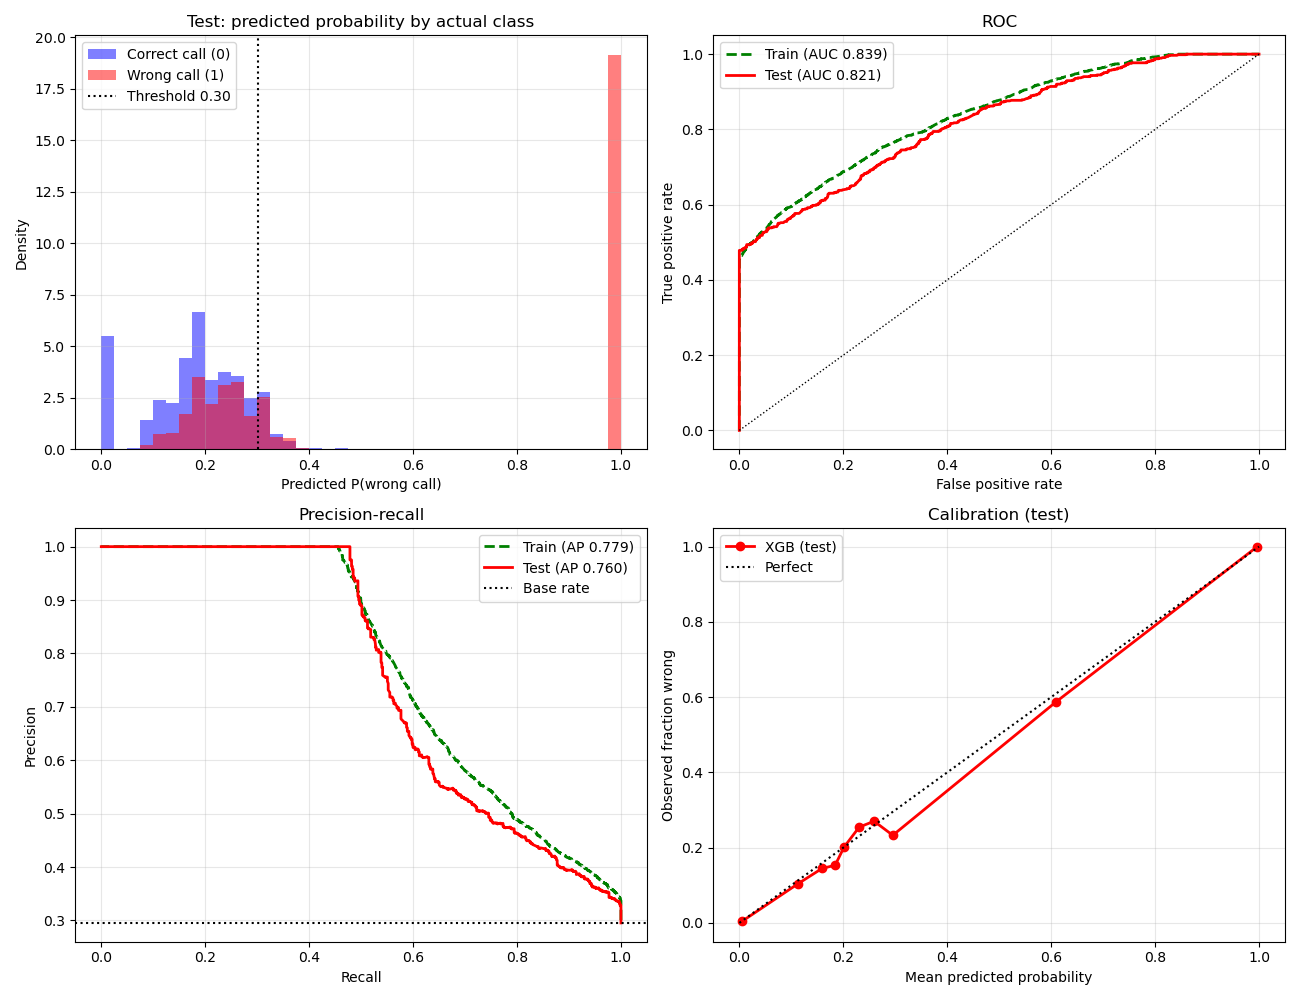

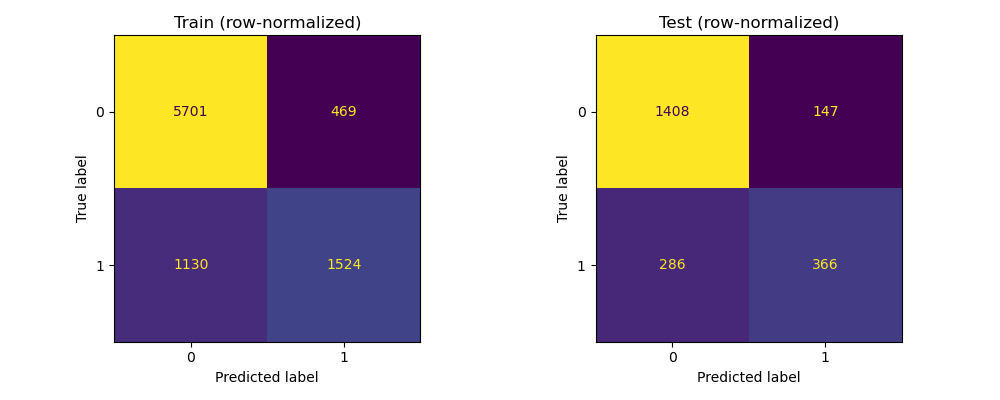

In [61]:
%matplotlib widget
fig, ax = plt.subplots(2, 2, figsize=(13, 10))

bins = np.linspace(0, 1, 41)
for cls, c, lbl in [(0, 'b', 'Correct call (0)'), (1, 'r', 'Wrong call (1)')]:
    ax[0, 0].hist(xgb_test_probs[test_response.values == cls], bins=bins, color=c, alpha=.5, density=True, label=lbl)
ax[0, 0].axvline(thr, color='black', linestyle=':', linewidth=1.5, label=f'Threshold {thr:.2f}')
ax[0, 0].set(xlabel='Predicted P(wrong call)', ylabel='Density', title='Test: predicted probability by actual class')
ax[0, 0].legend()

for yt, pp, st, lbl in [(train_response, xgb_train_probs, 'g--', 'Train'), (test_response, xgb_test_probs, 'r-', 'Test')]:
    f, t, _ = roc_curve(yt, pp)
    ax[0, 1].plot(f, t, st, linewidth=2, label=f'{lbl} (AUC {roc_auc_score(yt, pp):.3f})')
ax[0, 1].plot([0, 1], [0, 1], 'k:', linewidth=1)
ax[0, 1].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC'); ax[0, 1].legend()

for yt, pp, st, lbl in [(train_response, xgb_train_probs, 'g--', 'Train'), (test_response, xgb_test_probs, 'r-', 'Test')]:
    p_, r_, _ = precision_recall_curve(yt, pp)
    ax[1, 0].plot(r_, p_, st, linewidth=2, label=f'{lbl} (AP {average_precision_score(yt, pp):.3f})')
ax[1, 0].axhline(test_response.mean(), color='black', linestyle=':', linewidth=1.5, label='Base rate')
ax[1, 0].set(xlabel='Recall', ylabel='Precision', title='Precision-recall'); ax[1, 0].legend()

fp, mp = calibration_curve(test_response, xgb_test_probs, n_bins=10, strategy='quantile')
ax[1, 1].plot(mp, fp, 'ro-', linewidth=2, label='XGB (test)')
ax[1, 1].plot([0, 1], [0, 1], 'k:', linewidth=1.5, label='Perfect')
ax[1, 1].set(xlabel='Mean predicted probability', ylabel='Observed fraction wrong', title='Calibration (test)')
ax[1, 1].legend()

for a in ax.ravel(): a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../figs/XGB_WrongCall_Diagnostics.png", dpi=300)
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, yt, pl, ttl in [(ax[0], train_response, xgb_train_preds, 'Train'), (ax[1], test_response, xgb_test_preds, 'Test')]:
    ConfusionMatrixDisplay.from_predictions(yt, pl, ax=a, colorbar=False, 
    # normalize='true', 
    # values_format='.2f'
    )
    a.set_title(f'{ttl} (row-normalized)')
plt.tight_layout()
plt.savefig("../figs/XGB_WrongCall_Confusion.png", dpi=300)
plt.show()

In [ ]:
OUT_DIR = "../results/raw"
name = "missed_balls_"
os.makedirs(OUT_DIR, exist_ok=True)


preds_df = results.copy()

preds_path = os.path.join(OUT_DIR, f"xgb_{name}predictions_vs_actuals.csv")
preds_df.to_csv(preds_path, index=False)
print(f"Saved {len(preds_df):,} rows -> {preds_path}")
print(preds_df.head())

Saved 11,031 rows -> ../results/raw\xgb_missed_balls_predictions_vs_actuals.csv
   actual  pred_prob  pred_label  split
0       1   0.255480           0  train
1       0   0.268201           0  train
2       0   0.086214           0  train
3       0   0.158258           0  train
4       0   0.002614           0  train


In [65]:
OUT_DIR = "../results/stats"
os.makedirs(OUT_DIR, exist_ok=True)
def _metric_row(y_true, prob, pred, threshold):
    return {
        "threshold":  threshold,
        "log_loss":   log_loss(y_true, prob),
        "roc_auc":    roc_auc_score(y_true, prob),
        "pr_auc":     average_precision_score(y_true, prob),
        "accuracy":   accuracy_score(y_true, pred),
        "precision":  precision_score(y_true, pred, zero_division=0),
        "recall":     recall_score(y_true, pred, zero_division=0),
        "f1":         f1_score(y_true, pred, zero_division=0),
        "base_rate":  float(np.mean(y_true)),
        "n_rows":     len(y_true),
    }

metrics_df = pd.DataFrame([
    {"split": "train", **_metric_row(train_response, xgb_train_probs, xgb_train_preds, thr)},
    {"split": "test",  **_metric_row(test_response,  xgb_test_probs,  xgb_test_preds,  thr)},
])

metrics_path = os.path.join(OUT_DIR, f"xgb_{name}metrics.csv")
metrics_df.to_csv(metrics_path, index=False)
print(f"Saved metrics -> {metrics_path}")
display(metrics_df)

Saved metrics -> ../results/stats\xgb_missed_balls_metrics.csv


,split,threshold,log_loss,roc_auc,pr_auc,accuracy,precision,recall,f1,base_rate,n_rows
0,train,0.30242,0.379115,0.838559,0.779358,0.818790,0.764676,0.574228,0.655907,0.300771,8824
1,test,0.30242,0.377311,0.820928,0.759710,0.803806,0.713450,0.561350,0.628326,0.295424,2207
